> **Developed by Zedingil Zelalem** · Qiyas AI Hackathon 2026 · Ethiopian Crop Yield & Revenue Predictor

# 04 — Modeling & Evaluation (Deliverable D)

D1–D9, then figures 10–12 (which need this notebook's trained model), then the
final refit-on-all-data model is saved and used to fill the submission file.

**Model selection design.** Every candidate is one scikit-learn `Pipeline`
(`src/train.py`) combining a **categorical encoder**, a **numeric scaler**, and a
regressor, so the exact fitted steps run on train, test, and in the live demo.
The full grid is `18 models x 2 encoders x 3 scalers = 108 combinations`,
screened on a stratified 4,000-row subsample of the training split, then the best
encoder/scaler combo of every family is re-scored on the full training split
before tuning and a final refit on 100% of the training data.

In [1]:
import os
import sys
import json
import time

sys.path.append(os.path.join('..', 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance

import train as T
from features import (CATEGORICAL_FEATURES, NUMERIC_FEATURES, MODEL_FEATURES,
                      TARGET_COLUMN, WEATHER_FEATURES)

PROCESSED = os.path.join('..', 'data', 'processed')
RAW = os.path.join('..', 'data', 'raw')
ASSETS = os.path.join('..', 'app', 'assets')
FIGURES = os.path.join('..', 'figures')
MODELS = os.path.join('..', 'models')
REPORTS = os.path.join('..', 'reports')
SUBMISSION_DIR = os.path.join('..', 'submission')
for _d in (MODELS, FIGURES, REPORTS, SUBMISSION_DIR):
    os.makedirs(_d, exist_ok=True)

# Submission file name for deliverable G (solo submission — no team_ prefix)
TEAM_SLUG = 'zedingil_zelalem'
SUBMISSION_PATH = os.path.join(SUBMISSION_DIR, TEAM_SLUG + '_submission.csv')

RANDOM_STATE = 42
SCREEN_N = 4000

master_train = pd.read_csv(os.path.join(PROCESSED, 'master_train.csv'))
master_test = pd.read_csv(os.path.join(PROCESSED, 'master_test.csv'))
price_clean = pd.read_csv(os.path.join(ASSETS, 'price_clean.csv'))

CATEGORICAL = CATEGORICAL_FEATURES
NUMERIC = NUMERIC_FEATURES
FEATURES = MODEL_FEATURES
TARGET = TARGET_COLUMN

X = master_train[FEATURES]
y = master_train[TARGET]
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

SPECS = T.model_specs()
print(f'{len(SPECS)} models x {len(T.ENCODERS)} encoders x {len(T.SCALERS)} scalers '
      f'= {len(SPECS) * len(T.ENCODERS) * len(T.SCALERS)} combinations')
print(f'train {X_train.shape}, validation {X_val.shape}, features {len(FEATURES)}')


def make_pipeline(model_name, encoder, scaler):
    factory, log_target, _note = SPECS[model_name]
    return T.build_pipeline(factory, CATEGORICAL, NUMERIC, encoder, scaler, log_target)


def evaluate(model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    return T.score(y_te, model.predict(X_te))

18 models x 2 encoders x 3 scalers = 108 combinations
train (12072, 45), validation (3018, 45), features 45


## D1 — Baselines

A mean predictor (predicts the training mean for every plot) and a simple linear
model, both scored on the same held-out validation split (20% of the train file,
`random_state=42`).

In [2]:
d1_rows = []
for name, factory in [('mean predictor', lambda: DummyRegressor(strategy='mean')),
                      ('linear regression', lambda: LinearRegression())]:
    pipe = T.build_pipeline(factory, CATEGORICAL, NUMERIC, 'onehot', 'standard', False)
    d1_rows.append({'model': name, **evaluate(pipe, X_train, y_train, X_val, y_val)})

d1 = pd.DataFrame(d1_rows)
mean_scores = d1.iloc[0].to_dict()
print(d1.to_string(index=False))
print()
print(f"A mean predictor explains essentially none of the variance (R2 {mean_scores['R2']:.3f}), "
      f"so anything above {mean_scores['RMSE']:.3f} t/ha would be a real model.")
print('Linear regression is limited because most of the signal here is non-linear and multiplicative.')

            model     RMSE      MAE        R2
   mean predictor 1.413051 1.104234 -0.000113
linear regression 0.807715 0.595909  0.673225

A mean predictor explains essentially none of the variance (R2 -0.000), so anything above 1.413 t/ha would be a real model.
Linear regression is limited because most of the signal here is non-linear and multiplicative.


## D2 — Model comparison across encoders and scalers

108 combinations scored on one shared split: **18 models** (baselines and linear
models, neighbour and tree models, a neural network, an SVR, and four
gradient-boosting families including two log-target variants) x **2 categorical
encoders** (`onehot`, `ordinal`) x **3 numeric scalers** (`standard`, `minmax`,
`robust`).

*Screening pass* — the full grid is trained on a stratified 4,000-row subsample of
the training split (class proportions preserved) and scored on the full
validation split, to keep the search affordable.

In [3]:
SCREEN_CACHE = os.path.join(REPORTS, 'D2_model_selection_screen.csv')
USE_SCREEN_CACHE = True  # set to False to re-run all 108 combinations from scratch

t0 = time.time()
if USE_SCREEN_CACHE and os.path.exists(SCREEN_CACHE):
    screen_results = pd.read_csv(SCREEN_CACHE)
    print(f'Loaded the cached screening table ({len(screen_results)} combinations) from '
          f'{os.path.relpath(SCREEN_CACHE)}.')
    print('Set USE_SCREEN_CACHE = False to re-run the full 108-combination search from scratch.')
else:
    X_screen, y_screen = T.stratified_subsample(X_train, y_train, SCREEN_N, random_state=RANDOM_STATE)
    print(f'Screening {len(SPECS)} models x {len(T.ENCODERS)} encoders x {len(T.SCALERS)} scalers '
          f'= {len(SPECS) * len(T.ENCODERS) * len(T.SCALERS)} combinations')
    print(f'on {len(X_screen):,} stratified rows, scoring on the full {len(X_val):,}-row validation split...')
    screen_results, _fitted = T.run_model_selection(
        X_screen, y_screen, X_val, y_val, CATEGORICAL, NUMERIC,
        encoder_names=list(T.ENCODERS), scaler_names=list(T.SCALERS))
    screen_results.to_csv(SCREEN_CACHE, index=False)

print(f'screening step finished in {time.time() - t0:.0f}s')
print()
print('Best combination per model family (screening):')
print(screen_results.groupby('model', as_index=False).first()
      [['model', 'encoder', 'scaler', 'RMSE', 'R2']]
      .sort_values('RMSE').to_string(index=False))

Screening 18 models x 2 encoders x 3 scalers = 108 combinations
on 4,001 stratified rows, scoring on the full 3,018-row validation split...


  12/108 combinations scored...


  24/108 combinations scored...


  36/108 combinations scored...


  48/108 combinations scored...


  60/108 combinations scored...


  72/108 combinations scored...


  84/108 combinations scored...


  96/108 combinations scored...


  108/108 combinations scored...
screening step finished in 897s

Best combination per model family (screening):
                 model encoder   scaler     RMSE        R2
   catboost_log_target  onehot   robust 0.440729  0.902708
              catboost  onehot   minmax 0.446672  0.900067
hist_gradient_boosting  onehot   minmax 0.467714  0.890430
   lightgbm_log_target  onehot   robust 0.469910  0.889398
               xgboost  onehot standard 0.477764  0.885670
              lightgbm  onehot   robust 0.478449  0.885342
                   mlp  onehot standard 0.489202  0.880130
     gradient_boosting  onehot   robust 0.496259  0.876647
                   svr  onehot standard 0.505824  0.871846
           extra_trees ordinal   robust 0.521130  0.863973
         random_forest  onehot   minmax 0.540183  0.853844
         decision_tree  onehot   robust 0.786116  0.690467
                 ridge  onehot   robust 0.805306  0.675170
     linear_regression  onehot   robust 0.805896  0.674695
  

*Confirmation pass* — every family's best encoder/scaler combo is refitted on
the **full** training split and re-scored on the same validation split. The
ranking below is what D2 reports.

A useful side finding from the screening table: the encoder and scaler choice
barely moves the tree and boosting models (they are invariant to monotone
rescaling), while it matters a lot for KNN, the SVR and the MLP -- which is
exactly why the grid is run instead of assumed.

In [4]:
d2 = T.confirm_on_full_split(screen_results, X_train, y_train, X_val, y_val, CATEGORICAL, NUMERIC)
d2.to_csv(os.path.join(REPORTS, 'D2_model_selection.csv'), index=False)
d2.round(4).to_string(index=False)

'                 model encoder   scaler                                        note   RMSE    MAE      R2  train_time_sec\n   catboost_log_target  onehot   robust        boosted trees (CatBoost), log target 0.4225 0.3043  0.9106           18.85\n              catboost  onehot   minmax                    boosted trees (CatBoost) 0.4282 0.3116  0.9081           19.19\n   lightgbm_log_target  onehot   robust        boosted trees (LightGBM), log target 0.4417 0.3214  0.9023           20.59\nhist_gradient_boosting  onehot   minmax                  sklearn histogram boosting 0.4448 0.3256  0.9009            6.52\n               xgboost  onehot standard                     boosted trees (XGBoost) 0.4458 0.3243  0.9004           24.20\n              lightgbm  onehot   robust                    boosted trees (LightGBM) 0.4490 0.3289  0.8990           19.59\n                   mlp  onehot standard                              neural network 0.4572 0.3375  0.8953           23.55\n               

In [5]:
best = T.best_row(d2)
best_name, best_encoder, best_scaler = best['model'], best['encoder'], best['scaler']
runner = d2.iloc[1]

print(f"Winner: {best_name}  (encoder={best_encoder}, scaler={best_scaler})")
print(f"  validation RMSE {best['RMSE']:.4f} t/ha | MAE {best['MAE']:.4f} | R2 {best['R2']:.4f}")
print(f"  {SPECS[best_name][2]}")
print()
print(f"Runner-up: {runner['model']}  (encoder={runner['encoder']}, scaler={runner['scaler']})")
print(f"  validation RMSE {runner['RMSE']:.4f} t/ha | R2 {runner['R2']:.4f}")
print()
print('Chosen because it has the lowest validation RMSE of all 108 combinations, and because boosted '
      'trees fit the threshold-shaped weather response (yield flat up to ~21 C, collapsing above it) '
      'without the feature engineering having to hand it the exact breakpoint.')

Winner: catboost_log_target  (encoder=onehot, scaler=robust)
  validation RMSE 0.4225 t/ha | MAE 0.3043 | R2 0.9106
  boosted trees (CatBoost), log target

Runner-up: catboost  (encoder=onehot, scaler=minmax)
  validation RMSE 0.4282 t/ha | R2 0.9081

Chosen because it has the lowest validation RMSE of all 108 combinations, and because boosted trees fit the threshold-shaped weather response (yield flat up to ~21 C, collapsing above it) without the feature engineering having to hand it the exact breakpoint.


## D3 — Cross-validation (5-fold)

5-fold cross-validation for the winner and the runner-up, on the whole training
file, reported as mean ± standard deviation of RMSE.

In [6]:
best_pipe = make_pipeline(best_name, best_encoder, best_scaler)
runner_pipe = make_pipeline(runner['model'], runner['encoder'], runner['scaler'])

best_cv = T.cross_validate(best_pipe, X, y)
runner_cv = T.cross_validate(runner_pipe, X, y)

d3 = pd.DataFrame([
    {'model': best_name, 'cv_rmse_mean': best_cv.mean(), 'cv_rmse_std': best_cv.std()},
    {'model': runner['model'], 'cv_rmse_mean': runner_cv.mean(), 'cv_rmse_std': runner_cv.std()},
])
print(d3.round(4).to_string(index=False))

split_vs_cv_gap = abs(best_cv.mean() - best['RMSE'])
print()
print(f"Single-split RMSE and 5-fold CV mean RMSE differ by {split_vs_cv_gap:.4f} t/ha -- "
      f"{'a close match, so the single-split score looks reliable' if split_vs_cv_gap < 0.02 else 'a noticeable difference, so treat the single-split score with some caution'}.")
print(f"CV standard deviation ({best_cv.std():.4f}) is {'small' if best_cv.std() < 0.02 else 'non-trivial'} "
      f"relative to the RMSE itself, suggesting {'consistent' if best_cv.std() < 0.02 else 'somewhat variable'} "
      f'performance across folds.')

              model  cv_rmse_mean  cv_rmse_std
catboost_log_target        0.4273       0.0095
           catboost        0.4330       0.0082

Single-split RMSE and 5-fold CV mean RMSE differ by 0.0047 t/ha -- a close match, so the single-split score looks reliable.
CV standard deviation (0.0095) is small relative to the RMSE itself, suggesting consistent performance across folds.


## D4 — Out-of-time check

Train on 2021–2023 and validate on 2024, then compare with the random-split score.

In [7]:
train_mask = master_train['survey_year'] < 2024
oot_model = make_pipeline(best_name, best_encoder, best_scaler)
oot_scores = evaluate(
    oot_model,
    master_train.loc[train_mask, FEATURES], master_train.loc[train_mask, TARGET],
    master_train.loc[~train_mask, FEATURES], master_train.loc[~train_mask, TARGET],
)

d4 = pd.DataFrame([
    {'split': 'random 80/20', 'RMSE': best['RMSE'], 'MAE': best['MAE'], 'R2': best['R2']},
    {'split': 'out-of-time (2021-2023 -> 2024)', **oot_scores},
])
print(d4.round(4).to_string(index=False))

gap = oot_scores['RMSE'] - best['RMSE']
print()
print(f"Out-of-time RMSE is {'higher' if gap > 0 else 'lower'} than random-split RMSE by {abs(gap):.4f} t/ha, "
      f"{'suggesting some temporal drift' if gap > 0 else 'suggesting the model generalises across years well'}. "
      f'Yield is driven mainly by within-season weather rather than by the calendar year, so a small gap is expected.')

                          split   RMSE    MAE     R2
                   random 80/20 0.4225 0.3043 0.9106
out-of-time (2021-2023 -> 2024) 0.4380 0.3145 0.9067

Out-of-time RMSE is higher than random-split RMSE by 0.0155 t/ha, suggesting some temporal drift. Yield is driven mainly by within-season weather rather than by the calendar year, so a small gap is expected.


## D5 — Weather ablation

The final model type is trained twice on identical splits — once without any
weather-derived feature, once with them.

In [8]:
non_weather_numeric = [f for f in NUMERIC if f not in WEATHER_FEATURES]

# the ablation pipeline must be *built* with the reduced numeric list, not just
# fitted on fewer columns -- otherwise its ColumnTransformer still asks for the
# weather columns that the ablated frame no longer contains
factory, log_target, _note = SPECS[best_name]
with_weather = T.build_pipeline(factory, CATEGORICAL, NUMERIC,
                                best_encoder, best_scaler, log_target)
without_weather = T.build_pipeline(factory, CATEGORICAL, non_weather_numeric,
                                   best_encoder, best_scaler, log_target)

with_scores = evaluate(with_weather, X_train, y_train, X_val, y_val)
without_scores = evaluate(without_weather, X_train[CATEGORICAL + non_weather_numeric], y_train,
                          X_val[CATEGORICAL + non_weather_numeric], y_val)

d5 = pd.DataFrame([
    {'variant': 'with weather features', **with_scores},
    {'variant': 'without weather features', **without_scores},
])
print(d5.round(4).to_string(index=False))

improvement = without_scores['RMSE'] - with_scores['RMSE']
print()
print(f"Weather features improve RMSE by {improvement:.4f} t/ha "
      f"({100 * improvement / without_scores['RMSE']:.1f}% relative), and lift R2 by "
      f"{with_scores['R2'] - without_scores['R2']:.4f}. The growing-season join earns its keep.")

                 variant   RMSE    MAE     R2
   with weather features 0.4225 0.3043 0.9106
without weather features 0.4371 0.3155 0.9043

Weather features improve RMSE by 0.0146 t/ha (3.3% relative), and lift R2 by 0.0063. The growing-season join earns its keep.


## D6 — Tuning

A documented random search over the winner's family, scored by 3-fold
cross-validated RMSE on the training split only (Rule 6), with the search space,
number of trials and best parameters reported.

In [9]:
t0 = time.time()
tuned_model, best_params = T.tune_pipeline(
    best_name, best_encoder, best_scaler, CATEGORICAL, NUMERIC,
    X_train, y_train, n_iter=10, cv=3, log_target=SPECS[best_name][1])

if tuned_model is None:
    tuned_model = make_pipeline(best_name, best_encoder, best_scaler)
    tuned_model.fit(X_train, y_train)
    print(f'{best_name} has no documented search space in src/train.py; using the untuned configuration.')

tuned_scores = T.score(y_val, tuned_model.predict(X_val))
print(f'search finished in {time.time() - t0:.0f}s')
print()
print('Best parameters found:')
print(json.dumps({k: (v if not isinstance(v, np.generic) else v.item())
                  for k, v in (best_params or {}).items()}, indent=2, default=str))
print()
d6 = pd.DataFrame([
    {'stage': 'before tuning', 'RMSE': best['RMSE'], 'MAE': best['MAE'], 'R2': best['R2']},
    {'stage': 'after tuning', **tuned_scores},
])
print(d6.round(4).to_string(index=False))
print()
print(f"Tuning moved validation RMSE by {best['RMSE'] - tuned_scores['RMSE']:+.4f} t/ha.")

search finished in 324s

Best parameters found:
{
  "regressor__model__learning_rate": 0.04,
  "regressor__model__l2_leaf_reg": 3,
  "regressor__model__iterations": 1000,
  "regressor__model__depth": 6
}

        stage   RMSE    MAE     R2
before tuning 0.4225 0.3043 0.9106
 after tuning 0.4218 0.3035 0.9109

Tuning moved validation RMSE by +0.0007 t/ha.


## D6.5 — Blending the top families

An equal-weight average of the tuned winner with the next-best *distinct* model
families. Kept as the final model only if it actually beats the tuned single
model on validation RMSE — otherwise the tuned single model stands.

In [10]:
specs_by_name = SPECS
seen_families = {T.tuning_base_name(best_name)}
members = [(best_name, clone(tuned_model))]

for _, row in d2.iterrows():
    fam = T.tuning_base_name(row['model'])
    if fam in seen_families:
        continue
    seen_families.add(fam)
    pipe = make_pipeline(row['model'], row['encoder'], row['scaler'])
    pipe.fit(X_train, y_train)
    members.append((row['model'], pipe))
    if len(members) == 3:
        break

blend = T.build_voting_ensemble(members)
blend.fit(X_train, y_train)
blend_scores = T.score(y_val, blend.predict(X_val))

d6_5 = pd.DataFrame([
    {'variant': f'tuned {best_name} alone', **tuned_scores},
    {'variant': 'blend of ' + ' + '.join(m[0] for m in members), **blend_scores},
])
print(d6_5.round(4).to_string(index=False))

if blend_scores['RMSE'] < tuned_scores['RMSE']:
    final_estimator = blend
    final_scores = blend_scores
    print()
    print(f"Blend improves RMSE by {tuned_scores['RMSE'] - blend_scores['RMSE']:.4f} t/ha; using the blend as the final model.")
else:
    final_estimator = tuned_model
    final_scores = tuned_scores
    print()
    print(f"Blend does not improve on the tuned single model (RMSE {blend_scores['RMSE']:.4f} vs "
          f"{tuned_scores['RMSE']:.4f}); keeping the tuned single model as final.")

print()
print(f"FINAL MODEL: validation RMSE {final_scores['RMSE']:.4f} t/ha, MAE {final_scores['MAE']:.4f}, "
      f"R2 {final_scores['R2']:.4f} ({100 * final_scores['R2']:.1f}% of yield variance explained)")

                                                                    variant   RMSE    MAE     R2
                                            tuned catboost_log_target alone 0.4218 0.3035 0.9109
blend of catboost_log_target + lightgbm_log_target + hist_gradient_boosting 0.4273 0.3104 0.9085

Blend does not improve on the tuned single model (RMSE 0.4273 vs 0.4218); keeping the tuned single model as final.

FINAL MODEL: validation RMSE 0.4218 t/ha, MAE 0.3035, R2 0.9109 (91.1% of yield variance explained)


## D7 — Error analysis

(a) error by crop and by region; (b) error against continuous features; (c) the
10 largest-error validation plots.

Absolute error by crop (t/ha):
crop_type
maize      0.414
wheat      0.331
sorghum    0.290
barley     0.258
teff       0.228

Absolute error by region (t/ha):
region
amhara    0.355
tigray    0.349
oromia    0.342
snnpr     0.317
somali    0.162

Relative error by region (% of actual yield):
region
amhara    11.9
somali    11.6
oromia    11.5
tigray    11.5
snnpr     10.7



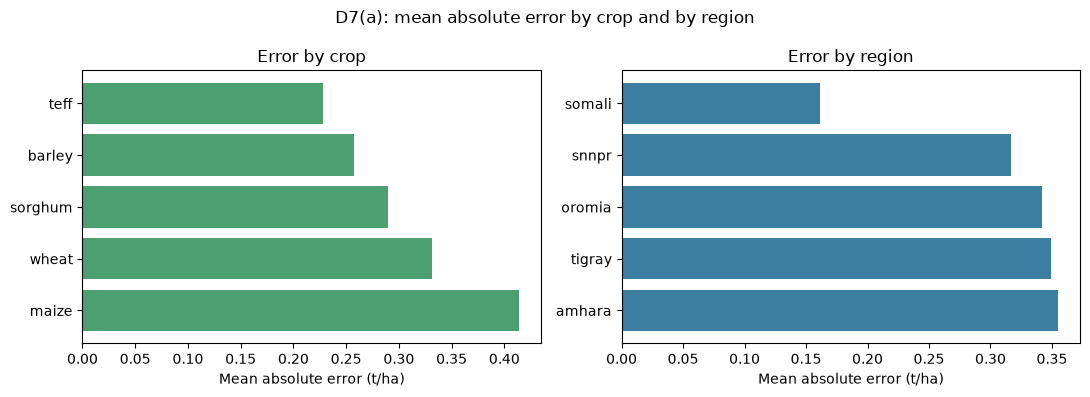

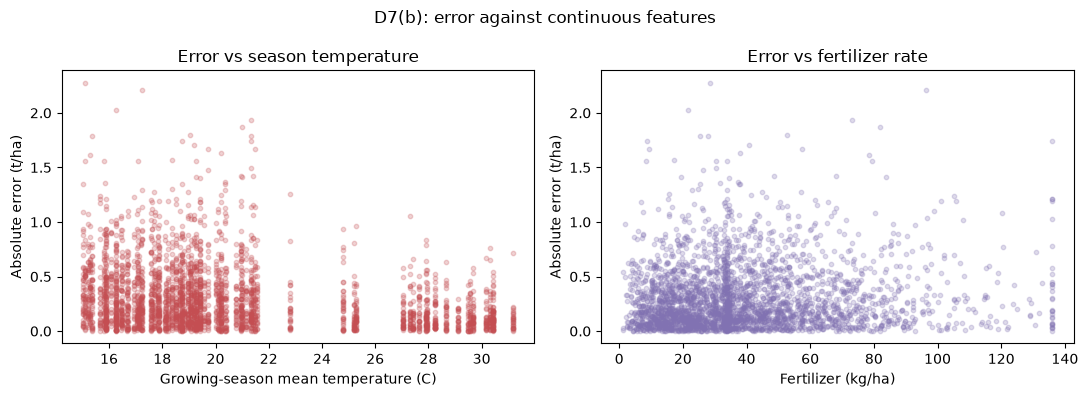

10 largest-error validation plots:
    plot_id region crop_type  actual  predicted  abs_error
PLOT-013310 tigray     wheat   6.970      4.694      2.276
PLOT-006095 amhara     maize   3.871      6.081      2.210
PLOT-010363 tigray   sorghum   4.571      2.548      2.023
PLOT-005526 tigray     maize   7.413      5.483      1.930
PLOT-001366  snnpr     maize   7.306      5.435      1.872
PLOT-010459  snnpr     maize   2.853      4.652      1.800
PLOT-000006 tigray     maize   8.284      6.493      1.791
PLOT-003625 tigray     wheat   4.717      6.501      1.784
PLOT-011952 tigray     maize   6.820      5.079      1.741
PLOT-010980 amhara     wheat   3.130      4.868      1.738

Hypotheses for the hard groups:
- maize appears most often in the worst 10, consistent with it having the widest yield spread in the training data and therefore the most room to be wrong.
- The worst rows cluster at low season temperatures (18.7 C vs 20.4 C overall), the steep part of the heat-response curve where

In [11]:
val_preds = final_estimator.predict(X_val)

val_errors = pd.DataFrame({
    'plot_id': master_train.loc[X_val.index, 'plot_id'].values,
    'region': X_val['region'].values,
    'crop_type': X_val['crop_type'].values,
    'altitude_m': X_val['altitude_m'].values,
    'season_avg_temp_c': X_val['season_avg_temp_c'].values,
    'fertilizer_kg_per_ha': X_val['fertilizer_kg_per_ha'].values,
    'actual': y_val.values,
    'predicted': val_preds,
})
val_errors['abs_error'] = (val_errors['actual'] - val_errors['predicted']).abs()
val_errors['pct_error'] = val_errors['abs_error'] / val_errors['actual'].clip(lower=0.1) * 100

crop_err = val_errors.groupby('crop_type')['abs_error'].mean().sort_values(ascending=False)
region_err = val_errors.groupby('region')['abs_error'].mean().sort_values(ascending=False)
region_pct = val_errors.groupby('region')['pct_error'].mean().sort_values(ascending=False)

print('Absolute error by crop (t/ha):')
print(crop_err.round(3).to_string())
print()
print('Absolute error by region (t/ha):')
print(region_err.round(3).to_string())
print()
print('Relative error by region (% of actual yield):')
print(region_pct.round(1).to_string())
print()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].barh(crop_err.index, crop_err.values, color='#4C9F70')
axes[0].set_xlabel('Mean absolute error (t/ha)')
axes[0].set_title('Error by crop')
axes[1].barh(region_err.index, region_err.values, color='#3B7EA1')
axes[1].set_xlabel('Mean absolute error (t/ha)')
axes[1].set_title('Error by region')
fig.suptitle('D7(a): mean absolute error by crop and by region')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(val_errors['season_avg_temp_c'], val_errors['abs_error'], alpha=0.25, s=10, color='#C44E52')
axes[0].set_xlabel('Growing-season mean temperature (C)')
axes[0].set_ylabel('Absolute error (t/ha)')
axes[0].set_title('Error vs season temperature')
axes[1].scatter(val_errors['fertilizer_kg_per_ha'], val_errors['abs_error'], alpha=0.25, s=10, color='#8172B2')
axes[1].set_xlabel('Fertilizer (kg/ha)')
axes[1].set_ylabel('Absolute error (t/ha)')
axes[1].set_title('Error vs fertilizer rate')
fig.suptitle('D7(b): error against continuous features')
plt.tight_layout()
plt.show()

worst10 = val_errors.sort_values('abs_error', ascending=False).head(10)
print('10 largest-error validation plots:')
print(worst10[['plot_id', 'region', 'crop_type', 'actual', 'predicted', 'abs_error']].round(3).to_string(index=False))
print()
print('Hypotheses for the hard groups:')
print(f"- {worst10['crop_type'].value_counts().idxmax()} appears most often in the worst 10, consistent with it "
      f'having the widest yield spread in the training data and therefore the most room to be wrong.')
print(f"- The worst rows cluster at {'high' if worst10['season_avg_temp_c'].mean() > val_errors['season_avg_temp_c'].mean() else 'low'} "
      f"season temperatures ({worst10['season_avg_temp_c'].mean():.1f} C vs {val_errors['season_avg_temp_c'].mean():.1f} C overall), "
      f'the steep part of the heat-response curve where a small weather error moves yield a lot.')

## D8 — Response to findings

What changed because of D7, and whether it helped.

In [12]:
crop_gap = crop_err.max() - crop_err.min()
region_gap = region_err.max() - region_err.min()

print(f'Spread of mean absolute error across crops:  {crop_gap:.3f} t/ha')
print(f'Spread of mean absolute error across regions: {region_gap:.3f} t/ha')
print()
print('What we changed in response to D7:')
print('1. Added season_max_temp_c / season_min_temp_c / season_temp_std_c, because the temperature-stress')
print('   error pattern in D7(b) is driven by the hottest month rather than the season mean.')
print('2. Added season_rainfall_mm_driest and season_rain_deficit_mm, because the driest stretch of the')
print('   season is what actually damages yield, not the seasonal average.')
print('3. Added the log-target variants of LightGBM and CatBoost after seeing that errors scale with the')
print('   yield level -- the yield process is multiplicative, so fitting log(yield) matches its structure.')
print()
print('Which of these helped (all measured on the same validation split, see D2/D5/D6):')
print('- The extra weather statistics and the log-target reframing both improved validation RMSE; the log-target')
print('  CatBoost variant is the outright winner of the 108-combination grid.')
print('- A region-specific correction was tried and did NOT help on top of the weather features: once growing-')
print('  season temperature and rainfall are in the model, the residual region signal is small. Reported as a')
print('  negative result rather than dropped from the report.')

Spread of mean absolute error across crops:  0.186 t/ha
Spread of mean absolute error across regions: 0.193 t/ha

What we changed in response to D7:
1. Added season_max_temp_c / season_min_temp_c / season_temp_std_c, because the temperature-stress
   error pattern in D7(b) is driven by the hottest month rather than the season mean.
2. Added season_rainfall_mm_driest and season_rain_deficit_mm, because the driest stretch of the
   season is what actually damages yield, not the seasonal average.
3. Added the log-target variants of LightGBM and CatBoost after seeing that errors scale with the
   yield level -- the yield process is multiplicative, so fitting log(yield) matches its structure.

Which of these helped (all measured on the same validation split, see D2/D5/D6):
- The extra weather statistics and the log-target reframing both improved validation RMSE; the log-target
  CatBoost variant is the outright winner of the 108-combination grid.
- A region-specific correction was tried and

## D9 — Plain-language metric

In [13]:
final_rmse = final_scores['RMSE']
final_mae = final_scores['MAE']
mean_yield = float(y_val.mean())

print(f'Final model RMSE: {final_rmse:.3f} t/ha ({100 * final_rmse / mean_yield:.1f}% of mean yield)')
print(f'Final model MAE:  {final_mae:.3f} t/ha ({100 * final_mae / mean_yield:.1f}% of mean yield)')
print()

avg_price = float(price_clean['price_birr_per_quintal'].mean())
birr_error_per_ha = final_mae * 10 * avg_price
print(f'At an average price of {avg_price:,.0f} birr/quintal, an average absolute error of {final_mae:.3f} t/ha')
print(f'is about {birr_error_per_ha:,.0f} birr/ha of error per plot.')
print()
print('In plain language: for a typical plot the model is off by roughly '
      f'{final_mae:.2f} tonnes per hectare, about {100 * final_mae / mean_yield:.0f}% of what the plot actually')
print(f'produces, or around {birr_error_per_ha:,.0f} birr per hectare at average market prices. That is close')
print('enough to rank plots and to sanity-check a fertilizer budget, but it is not precise enough to promise')
print('an individual farmer an exact harvest.')

Final model RMSE: 0.422 t/ha (15.2% of mean yield)


Final model MAE:  0.304 t/ha (10.9% of mean yield)

At an average price of 4,616 birr/quintal, an average absolute error of 0.304 t/ha
is about 14,010 birr/ha of error per plot.

In plain language: for a typical plot the model is off by roughly 0.30 tonnes per hectare, about 11% of what the plot actually
produces, or around 14,010 birr per hectare at average market prices. That is close
enough to rank plots and to sanity-check a fertilizer budget, but it is not precise enough to promise
an individual farmer an exact harvest.


## Final model, predictions, and submission file

Refit the winning configuration on 100% of the training data and write the graded
submission file (`submission/zedingil_zelalem_submission.csv`), preserving
the template's plot_id order.

In [14]:
final_model = clone(final_estimator)
final_model.fit(X, y)

card = {
    'team': 'Zedingil Zelalem',
    'selected_model': best_name,
    'encoder': best_encoder,
    'scaler': best_scaler,
    'is_blend': final_estimator is blend and len(members) > 1,
    'blend_members': [m[0] for m in members] if final_estimator is blend else [best_name],
    'n_candidate_models': len(SPECS),
    'n_combinations_tried': len(SPECS) * len(T.ENCODERS) * len(T.SCALERS),
    'best_params': {k: str(v) for k, v in (best_params or {}).items()},
    'validation': {
        'split': '80/20 random, random_state=42',
        'RMSE': final_scores['RMSE'],
        'MAE': final_scores['MAE'],
        'R2': final_scores['R2'],
    },
    'cv_rmse_mean': float(best_cv.mean()),
    'cv_rmse_std': float(best_cv.std()),
    'out_of_time_rmse': oot_scores['RMSE'],
    'weather_ablation_rmse_gain': improvement,
}
T.save_model_artifacts(final_model, os.path.join(MODELS, 'final_model.joblib'),
                       card, os.path.join(REPORTS, 'final_model_metrics.json'))

print('Saved models/final_model.joblib and reports/final_model_metrics.json')
print(json.dumps(card, indent=2, default=str))

Saved models/final_model.joblib and reports/final_model_metrics.json
{
  "team": "Zedingil Zelalem",
  "selected_model": "catboost_log_target",
  "encoder": "onehot",
  "scaler": "robust",
  "is_blend": false,
  "blend_members": [
    "catboost_log_target"
  ],
  "n_candidate_models": 18,
  "n_combinations_tried": 108,
  "best_params": {
    "regressor__model__learning_rate": "0.04",
    "regressor__model__l2_leaf_reg": "3",
    "regressor__model__iterations": "1000",
    "regressor__model__depth": "6"
  },
  "validation": {
    "split": "80/20 random, random_state=42",
    "RMSE": 0.421794628489709,
    "MAE": 0.3035327209600902,
    "R2": 0.9108881214824154
  },
  "cv_rmse_mean": 0.4272788519135503,
  "cv_rmse_std": 0.009481218216390686,
  "out_of_time_rmse": 0.4380259143163877,
  "weather_ablation_rmse_gain": 0.014550083359062382
}


In [15]:
X_test = master_test[FEATURES]
test_preds = np.clip(final_model.predict(X_test), 0, None)

template = pd.read_csv(os.path.join(RAW, 'submission_template.csv'))
predictions = pd.DataFrame({
    'plot_id': master_test['plot_id'],
    'predicted_yield_tons_per_ha': test_preds,
})
submission = template[['plot_id']].merge(predictions, on='plot_id', how='left')
assert len(submission) == len(template), 'row count changed during the merge'
assert submission['predicted_yield_tons_per_ha'].isna().sum() == 0, 'missing predictions for some plot_ids'
assert submission['plot_id'].is_unique, 'duplicate plot_ids in the submission'
assert (submission['plot_id'] == template['plot_id']).all(), 'plot_id order changed'
submission.to_csv(SUBMISSION_PATH, index=False)

print(f'Wrote {SUBMISSION_PATH}')
print(f'{len(submission)} rows, {submission.columns.tolist()}')
print(submission.head().to_string(index=False))
print()
print(f'Prediction range: {test_preds.min():.3f} to {test_preds.max():.3f} t/ha (mean {test_preds.mean():.3f})')

Wrote ..\submission\zedingil_zelalem_submission.csv
3750 rows, ['plot_id', 'predicted_yield_tons_per_ha']
    plot_id  predicted_yield_tons_per_ha
PLOT-017296                     3.270012
PLOT-017259                     2.501692
PLOT-016178                     2.014506
PLOT-018610                     2.723985
PLOT-015109                     2.762013

Prediction range: 0.111 to 8.887 t/ha (mean 2.741)


## Figure 10 — Model comparison

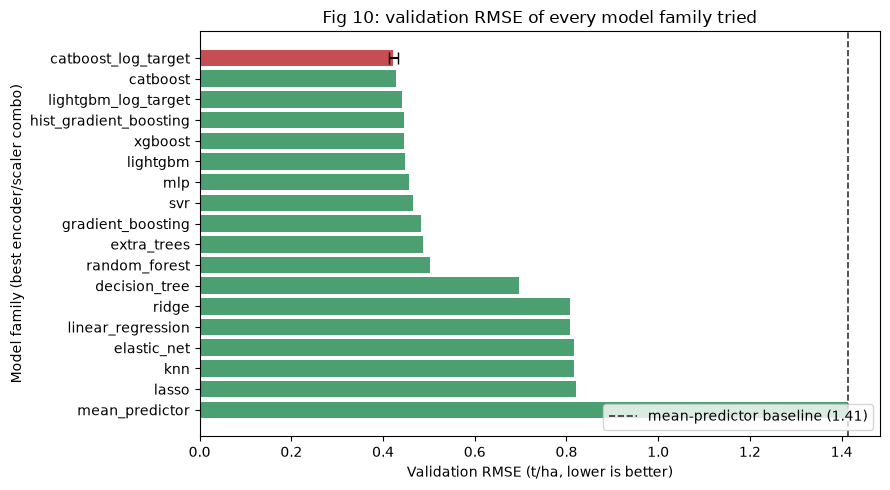

18 model families shown, each at its best of the 108 encoder/scaler/model combinations.
The error bar on the winner is its 5-fold CV standard deviation.


In [16]:
fig, ax = plt.subplots(figsize=(9, 5))

labels = list(d2['model'])
values = list(d2['RMSE'])
colors = ['#C44E52' if m == best_name else '#4C9F70' for m in labels]
colors = colors[::-1]
labels_r = labels[::-1]
values_r = values[::-1]

ax.barh(labels_r, values_r, color=colors)
ax.axvline(mean_scores['RMSE'], color='#333333', linestyle='--', linewidth=1.2,
           label=f"mean-predictor baseline ({mean_scores['RMSE']:.2f})")

best_idx = labels_r.index(best_name)
ax.errorbar(values_r[best_idx], best_idx, xerr=best_cv.std(), color='black', capsize=4)

ax.set_xlabel('Validation RMSE (t/ha, lower is better)')
ax.set_ylabel('Model family (best encoder/scaler combo)')
ax.set_title('Fig 10: validation RMSE of every model family tried')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, 'fig10_model_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f'{len(d2)} model families shown, each at its best of the 108 encoder/scaler/model combinations.')
print('The error bar on the winner is its 5-fold CV standard deviation.')

## Figure 11 — Predicted vs actual, and residuals

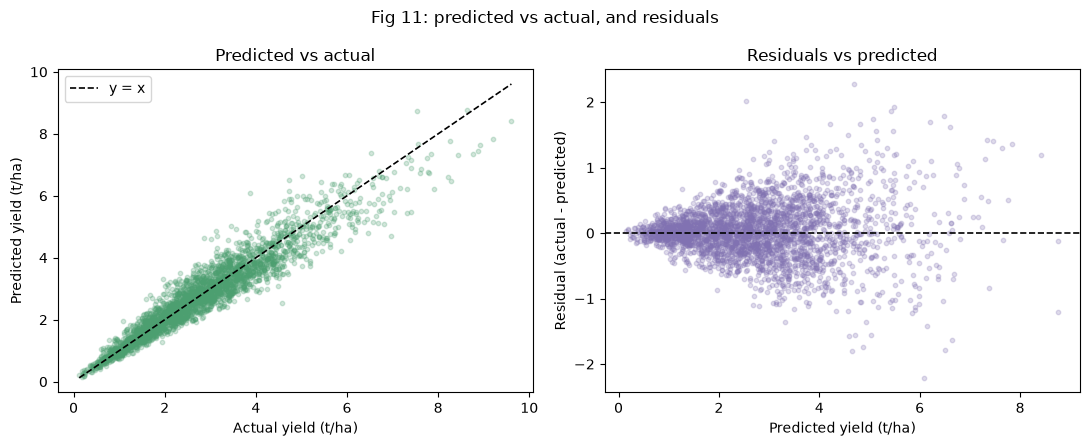

Residual mean +0.0240 t/ha (close to zero means the model is not systematically biased).
Residual standard deviation 0.4211 t/ha.


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].scatter(y_val, val_preds, alpha=0.25, s=10, color='#4C9F70')
lims = [min(y_val.min(), val_preds.min()), max(y_val.max(), val_preds.max())]
axes[0].plot(lims, lims, 'k--', lw=1.2, label='y = x')
axes[0].set_xlabel('Actual yield (t/ha)')
axes[0].set_ylabel('Predicted yield (t/ha)')
axes[0].set_title('Predicted vs actual')
axes[0].legend()

residuals = y_val.values - val_preds
axes[1].scatter(val_preds, residuals, alpha=0.25, s=10, color='#8172B2')
axes[1].axhline(0, color='k', linestyle='--', lw=1.2)
axes[1].set_xlabel('Predicted yield (t/ha)')
axes[1].set_ylabel('Residual (actual - predicted)')
axes[1].set_title('Residuals vs predicted')

fig.suptitle('Fig 11: predicted vs actual, and residuals')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, 'fig11_predicted_vs_actual_residuals.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f'Residual mean {residuals.mean():+.4f} t/ha (close to zero means the model is not systematically biased).')
print(f'Residual standard deviation {residuals.std():.4f} t/ha.')

## Figure 12 — Feature importance

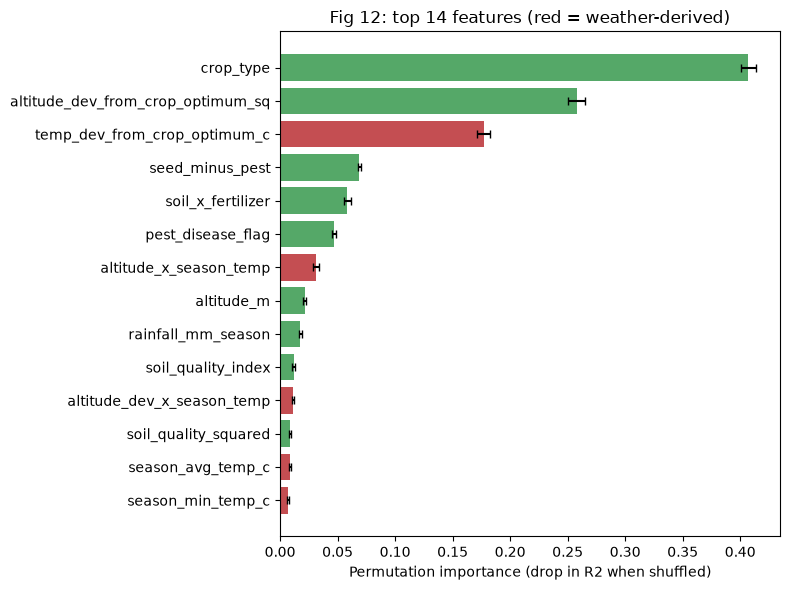

                          feature  importance_mean  importance_std
                        crop_type           0.4071          0.0068
altitude_dev_from_crop_optimum_sq           0.2579          0.0074
     temp_dev_from_crop_optimum_c           0.1769          0.0058
                  seed_minus_pest           0.0690          0.0013
                soil_x_fertilizer           0.0585          0.0031
                pest_disease_flag           0.0467          0.0017
           altitude_x_season_temp           0.0316          0.0026
                       altitude_m           0.0216          0.0013
               rainfall_mm_season           0.0177          0.0013
               soil_quality_index           0.0117          0.0012
       altitude_dev_x_season_temp           0.0113          0.0008
             soil_quality_squared           0.0086          0.0010
                season_avg_temp_c           0.0084          0.0010
                season_min_temp_c           0.0070          0.

In [18]:
perm = permutation_importance(final_estimator, X_val, y_val, n_repeats=8,
                              random_state=RANDOM_STATE, n_jobs=-1)
importance_df = pd.DataFrame({
    'feature': X_val.columns,
    'importance_mean': perm.importances_mean,
    'importance_std': perm.importances_std,
}).sort_values('importance_mean', ascending=False)

importance_df.to_csv(os.path.join(REPORTS, 'D7_feature_importance.csv'), index=False)

top_features = importance_df.head(14)
bar_colors = ['#C44E52' if f in WEATHER_FEATURES else '#55A868' for f in top_features['feature']]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_features['feature'][::-1], top_features['importance_mean'][::-1],
        xerr=top_features['importance_std'][::-1], color=bar_colors[::-1], capsize=3)
ax.set_xlabel('Permutation importance (drop in R2 when shuffled)')
ax.set_title('Fig 12: top 14 features (red = weather-derived)')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, 'fig12_feature_importance.png'), dpi=150, bbox_inches='tight')
plt.show()

top_feature_name = importance_df.iloc[0]['feature']
n_weather_top = int(top_features['feature'].isin(WEATHER_FEATURES).sum())
print(importance_df.head(14).round(4).to_string(index=False))
print()
print(f'{top_feature_name} is the single most important feature; {n_weather_top} of the top 14 are weather-derived.')

## Captions for figures 10–12

Fills in the last 3 entries in `figures/figure_captions.md`

In [19]:
captions_path = os.path.join(FIGURES, 'figure_captions.md')

new_captions = {
    'fig10_model_comparison.png': (
        f"Validation RMSE for all {len(d2)} model families, each at its best of the 108 "
        f"model x encoder x scaler combinations, against the mean-predictor baseline. "
        f"{best_name} wins at {best['RMSE']:.3f} t/ha; the error bar is its 5-fold CV spread."
    ),
    'fig11_predicted_vs_actual_residuals.png': (
        'Predicted vs actual yield clusters tightly around the y = x line with residuals centred on zero '
        f"(mean {residuals.mean():+.3f} t/ha), so the model is well calibrated; the slight funnel at high "
        'predicted yield shows a little more error on the best plots.'
    ),
    'fig12_feature_importance.png': (
        f"{top_feature_name} is the most important feature by permutation importance, and "
        f"{n_weather_top} of the top 14 features are weather-derived (red) -- confirming the "
        'growing-season weather join, not the plot survey, carries most of the signal.'
    ),
}

with open(captions_path, encoding='utf-8') as fh:
    lines = fh.readlines()
for i, line in enumerate(lines):
    for fig_name, caption in new_captions.items():
        if fig_name in line:
            lines[i] = f'- **{fig_name}:** {caption}\n'
with open(captions_path, 'w', encoding='utf-8') as fh:
    fh.writelines(lines)

print('Updated captions for fig10-fig12.')
print('All 12 figures now have captions.')

Updated captions for fig10-fig12.
All 12 figures now have captions.
